# DSA 4060XA – Week 6 Guided Evaluation Lab
## Evaluating Recommender Systems: Popularity Baseline • Content-Based • Item-Based CF

**Name:** Abdirisak Hussein    **Student ID:** 668776

**Objective:** compare three recommenders using rating-prediction metrics (MAE, RMSE), ranking metrics (Precision@K, Recall@K, NDCG@K) and beyond-accuracy metrics (coverage, novelty, diversity), then recommend a model for a stated business objective.

## Step 1 – Import the Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

## Step 2 – Load and Inspect the Data

In [2]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")
display(movies.head())
display(ratings.head())
print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))
print("Missing values:", int(ratings.isna().sum().sum()), "| Duplicate user-movie pairs:", int(ratings.duplicated(["user_id","movie_id"]).sum()))
print("Ratings per user:", ratings.groupby("user_id").size().unique())

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120
Missing values: 0 | Duplicate user-movie pairs: 0
Ratings per user: [10]



1. **One row in `movies`** is one movie (catalogue item) with its `movie_id`, `title` and list of `genres`.
2. **One row in `ratings`** is one rating event: a specific user rated a specific movie with a score at a point in time (`timestamp`).
3. There are **12 unique users**, **20 unique movies** and **120 ratings** (exactly 10 ratings per user; no missing values or duplicate user movie pairs).
4. The rating is **explicit feedback**: users directly state how much they liked a movie.
5. The scale is **1–5** (integer stars). In this data only 2, 3, 4 and 5 actually occur.

## Step 3 – Inspect Rating Behaviour

,count
rating,
2,29
3,49
4,28
5,14


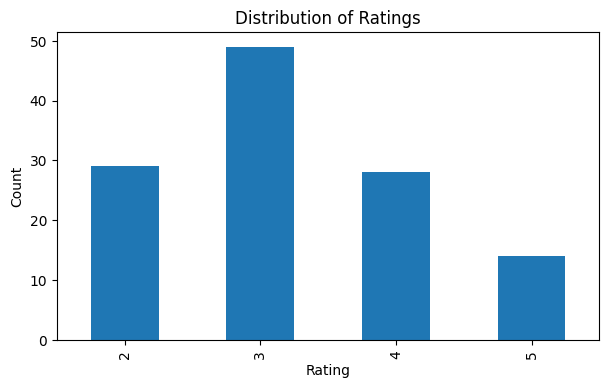

Share of ratings >= 4: 0.35


In [3]:
display(ratings["rating"].value_counts().sort_index())
plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()
print("Share of ratings >= 4:", round((ratings["rating"] >= 4).mean(), 3))

**Interpretation.** Middle ratings dominate: 3 is the most common score (49 of 120), followed by 2 (29) and 4 (28), while 5 is the rarest (14) and nobody gave a 1. Only about 35% of ratings are 4 or 5. Because the ratings are clustered around 3, a model that predicts values near the mean can get a deceptively low MAE, and because "relevant" items (rating ≥ 4) are a minority, Top-N precision will be low and hard to improve, so the metrics need careful reading.

## Step 4 – Create a Train/Test Split (leave-last-out per user)

In [4]:
ratings = ratings.sort_values(["user_id", "timestamp"])
test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())
print("Test rating counts:", test["rating"].value_counts().sort_index().to_dict())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


Test rating counts: {2: 4, 3: 3, 4: 3, 5: 2}


## Step 5 – Build a Popularity Baseline

In [5]:
global_mean = train["rating"].mean()

movie_stats = (
    train.groupby("movie_id")
    .agg(mean_rating=("rating", "mean"), rating_count=("rating", "size"))
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

display(movie_stats.sort_values(["mean_rating", "rating_count"], ascending=[False, False]).head(10))

movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()
baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)
print("Global training mean:", round(global_mean, 3))

,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


Global training mean: 3.222


## Step 6 – Evaluate the Baseline with MAE and RMSE

In [6]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(baseline_test["rating"], baseline_test["prediction"])
print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


**Interpretation.** A baseline MAE of about 1.09 means the movie-average predictor is off by roughly one rating point on average. That is large on a 1–5 scale.

## Step 7 – Item Features for Content-Based Filtering

In [7]:
genre_features = movies["genres"].str.get_dummies(sep="|")
content_items = pd.concat([movies[["movie_id", "title"]], genre_features], axis=1)
genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]
display(content_items.head())
print("Genres:", genre_columns)

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


Genres: ['Action', 'Adventure', 'Comedy', 'Crime', 'Drama', 'Family', 'Mystery', 'Romance', 'Sci-Fi']


## Step 8 – User Preference Profile

In [8]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)
display(pd.Series(profile, index=genre_columns).sort_values(ascending=False))

display(train[train["user_id"] == 1].merge(movies, on="movie_id")[["title", "genres", "rating"]]
        .sort_values("rating", ascending=False))

,0
Drama,1.666667
Sci-Fi,1.000000
Comedy,0.888889
Romance,0.666667
Action,0.555556
Family,0.555556
Crime,0.333333
Mystery,0.333333
Adventure,0.222222


,title,genres,rating
2,Galaxy Mission,Action|Sci-Fi,5
6,Digital Dreams,Sci-Fi|Drama,4
0,Love in Nairobi,Romance|Drama,3
3,Wedding Weekend,Romance|Comedy,3
1,Hidden Truth,Drama|Mystery,3
4,City Detectives,Crime|Drama,3
8,Family Weekend,Comedy|Family,3
5,Home Again,Family|Drama,2
7,Weekend Escape,Comedy|Adventure,2


## Step 9 – Content-Based Rating Prediction

In [9]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train), axis=1)

content_mae, content_rmse = rating_metrics(content_test["rating"], content_test["prediction"])
print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


## Step 10 – Item-Based Collaborative Filtering

In [10]:
user_item = train.pivot_table(index="user_id", columns="movie_id", values="rating")
item_user = user_item.T.fillna(0)
item_similarity = pd.DataFrame(
    cosine_similarity(item_user), index=item_user.index, columns=item_user.index)
item_similarity.iloc[:5, :5]

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


## Step 11 – Item-Based Rating Prediction

In [11]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    weighted_sum = 0.0
    similarity_sum = 0.0
    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim
    if similarity_sum == 0:
        return global_mean
    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train), axis=1)

cf_mae, cf_rmse = rating_metrics(cf_test["rating"], cf_test["prediction"])
print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))
print("Predictions that fell back to the global mean:", int((cf_test["prediction"] == global_mean).sum()))

CF MAE: 0.924
CF RMSE: 1.07
Predictions that fell back to the global mean: 0


## Step 12 – Compare Rating Prediction Metrics

In [12]:
rating_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})
rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


The best MAE: Item-based CF (≈0.924), then comes Popularity (≈1.086) and then Content-Based (≈1.094). The best RMSE: Item-based CF (≈1.070), then comes Popularity (≈1.201) and then Content-Based (≈1.381). Is any of the advanced models better than the basic one? Item-Based CF is better than the baseline in both metrics (≈15% lower MAE, ≈11% lower RMSE), but there are only 12 test ratings, which is indicative, but not very significant. Content-Based model is not better than the baseline: its MAE is ≈equivalent and RMSE is obviously worse because of very small rating predictions (e.g. ≈1.6 – 2.0) for highly rated movies. Why not to use only one of them? MAE and RMSE have different impact on errors (RMSE punishes for high error), both metrics show rating accuracy but do not show ranking effectiveness or usefulness of recommendations at all (a model can be accurate in rating predictions, but poor in ranking).

## Step 13 – From Rating Prediction to Ranking Evaluation

In [13]:
test["relevant"] = test["rating"] >= 4
test[["user_id", "movie_id", "rating", "relevant"]].head(12)

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False
59,6,2,5,True
69,7,3,2,False
79,8,12,2,False
89,9,16,2,False
99,10,19,3,False


## Step 14 – Top-N Recommendation Functions

In [14]:
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(train.loc[train["user_id"] == user_id, "movie_id"])
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats.sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

title_map = movies.set_index("movie_id")["title"].to_dict()
for name, fn in [("Popularity", recommend_popularity), ("Content", recommend_content), ("Collaborative", recommend_cf)]:
    ids = fn(1)
    print(f"{name:14s}", ids, [title_map[i] for i in ids])

Popularity     [6, 18, 16] ['Broken Hearts', 'The Promise', 'Campus Life']
Content        [16, 6, 18] ['Campus Life', 'Broken Hearts', 'The Promise']
Collaborative  [12, 11, 18] ['The Last Case', 'Laugh Out Loud', 'The Promise']


Discussion. For User 1, there are three lists as follows: Popularity: Broken Hearts, The Promise, Campus Life; Content: Campus Life, Broken Hearts, The Promise (it should be noted that the movies on both lists are the same, but in different order); CF: The Last Case, Laugh Out Loud, The Promise. It appears that CF list is the most unique one, since it is the only list that does not look like popularity list. It is simply due to the fact that content list coincides with popularity list in this particular case due to genres of popular movies, which are Drama/Romance, and this is the favorite genre of User 1.

## Step 15 – Precision@K, Recall@K and NDCG@K

In [15]:
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)
    ideal_hits = min(len(relevant), k)
    idcg = sum(1 / np.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3, threshold=4):
    rows = []
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[(test["user_id"] == user_id) & (test["rating"] >= threshold), "movie_id"].tolist()
        if not relevant:
            continue
        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)
        rows.append({"user_id": user_id, "Precision@K": precision, "Recall@K": recall,
                     "NDCG@K": ndcg_at_k(recs, relevant, k)})
    result = pd.DataFrame(rows)
    return {f"Precision@{k}": result["Precision@K"].mean(),
            f"Recall@{k}": result["Recall@K"].mean(),
            f"NDCG@{k}": result["NDCG@K"].mean()}

pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank},
])
print("Users with a relevant held-out item:", int(test["relevant"].sum()), "of", len(test))
ranking_results

Users with a relevant held-out item: 5 of 12


,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


Interpreting the table. As only 5 users have a relevant hold-out item, all the models are evaluated based on 5 users with 1 relevant item for each of them (max Recall@3 is 1.0 and max Precision@3 is 0.33 for each user). Content-Based has the highest ranking performance (0.067 Precision, 0.20 Recall, 0.20 NDCG), while Popularity has the same performance on precision and recall but ranks the hit item lower (0.10 NDCG). Item-Based CF gets 0 on all measures, despite having the highest MAE and RMSE values. This is precisely the conclusion of the lab: good rating accuracy does not mean good ranking performance. (In CF, the predicted rating is computed by a weighed average of the user’s own ratings, and therefore items that resemble just one highly-rated movie can come up to the top; such ranking is random.) With no more than one hit per model, the difference of one user matters a lot here.

## Step 16 – Catalogue Coverage

In [16]:
def catalogue_coverage(recommender, k=3):
    recommended = set()
    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [catalogue_coverage(recommend_popularity),
                 catalogue_coverage(recommend_content),
                 catalogue_coverage(recommend_cf)]
})
coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


## Step 17 – Novelty

In [17]:
pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)

def average_novelty(recommender, k=3):
    values = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [average_novelty(recommend_popularity),
                average_novelty(recommend_content),
                average_novelty(recommend_cf)]
})
novelty_results

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


## Step 18 – Diversity

In [18]:
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index, columns=item_feature_matrix.index)

def list_diversity(movie_ids):
    sims = []
    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(genre_similarity.loc[movie_ids[i], movie_ids[j]])
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=3):
    return np.mean([list_diversity(recommender(user_id, k)) for user_id in train["user_id"].unique()])

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [average_diversity(recommend_popularity),
                  average_diversity(recommend_content),
                  average_diversity(recommend_cf)]
})
diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


## Step 19 – Unified Evaluation Table

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.086,1.201,0.067,0.2,0.1,0.35,1.689,0.736
1,Content-Based,1.094,1.381,0.067,0.2,0.2,0.70,1.344,0.542
2,Item-Based CF,0.924,1.070,0.000,0.0,0.0,0.85,1.695,0.780


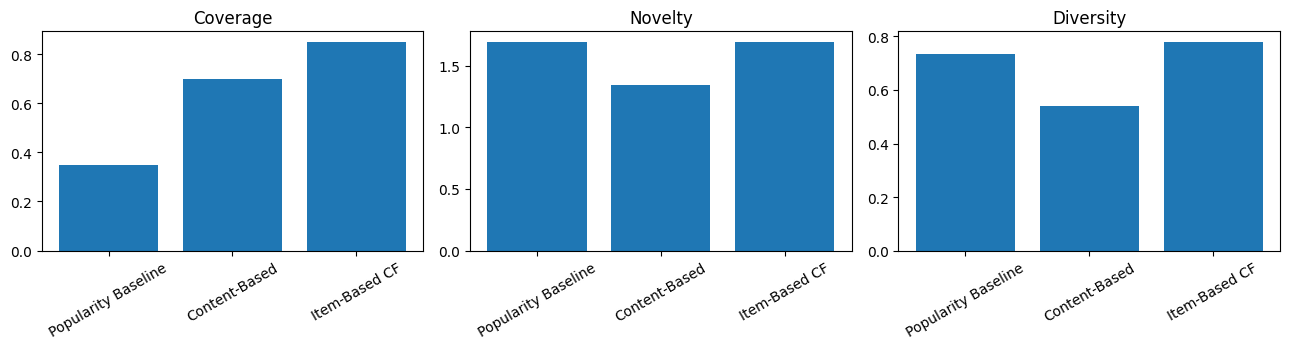

In [19]:
summary = (rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model"))
display(summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["Coverage", "Novelty", "Diversity"]):
    ax.bar(summary["Model"], summary[col])
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Results beyond accuracy.

Coverage: Popularity reveals just 35% of the catalogue (7 out of 20 movies; it suggests almost the same movies to everyone), Content-Based 70%, and Item-Based CF 85%.
Novelty: Both CF (1.69) and Popularity (1.69) have almost equal values; the smallest value (1.34) is for Content-Based, which means that it prefers movies that many users have already rated. The novelty of Popularity is not quite low in this case since the catalogue is small and even the highest-rated movies have not been rated by all users.
Diversity: CF movie lists have the largest diversity (0.78), Popularity 0.74, and Content-Based the smallest one (0.54).

## Step 20 – Trade-Offs

- **Accuracy ≠ ranking:** CF has the best MAE/RMSE but zero Top-3 hits; Content-Based has the worst RMSE but the best ranking.
- **Coverage vs. accuracy:** CF has the highest coverage, novelty and diversity but delivered no relevant recommendations; Popularity has low coverage and gives everyone nearly the same list.
- **Explainability vs. personalisation:** Popularity is the easiest to explain but least personalised.
- **Diversity vs. focus:** Content-Based gives focused lists (lowest diversity) that matched held-out likes best.

## Step 21 – Final Business Scenario
> "We want users to discover relevant movies, but we do not want the same popular titles to dominate every recommendation list."

10. **Model chosen: Content-Based filtering** (as the primary model).
11. **Deciding metrics:** (a) NDCG@3 / Precision@3 / Recall@3, where it is the only model that beats the baseline on ranking and so delivers relevant movies; (b) catalogue coverage, where it is double the popularity baseline (70% vs 35%), which addresses the "same popular titles" concern. Novelty and diversity were secondary.
12. **Trade-off accepted:** Content-Based has the lowest novelty (1.34) and diversity (0.54) and the worst RMSE. Lists are more genre-homogeneous, and the model cannot learn tastes beyond genre. Item-Based CF would be better on coverage, novelty and diversity, but it produced no relevant items in Top-3 here, so choosing it would mean sacrificing the "relevant" half of the objective. A practical improvement would be a **hybrid** (content score plus CF/diversity re-ranking) once more data is available.
13. **Limitation:** The test set holds one interaction per user (12 in total) and only 5 relevant items, so a single user changes the ranking metrics by up to 20 percentage points. The conclusions are indicative, not statistically reliable.

## Step 22 – Extension Challenge: Option A (Change K)
Evaluate K = 1, 3 and 5.

,K,Model,Precision@K,Recall@K,NDCG@K
0,1,Popularity Baseline,0.000,0.0,0.000
1,1,Content-Based,0.200,0.2,0.200
2,1,Item-Based CF,0.000,0.0,0.000
3,3,Popularity Baseline,0.067,0.2,0.100
4,3,Content-Based,0.067,0.2,0.200
5,3,Item-Based CF,0.000,0.0,0.000
6,5,Popularity Baseline,0.040,0.2,0.100
7,5,Content-Based,0.080,0.4,0.277
8,5,Item-Based CF,0.040,0.2,0.077


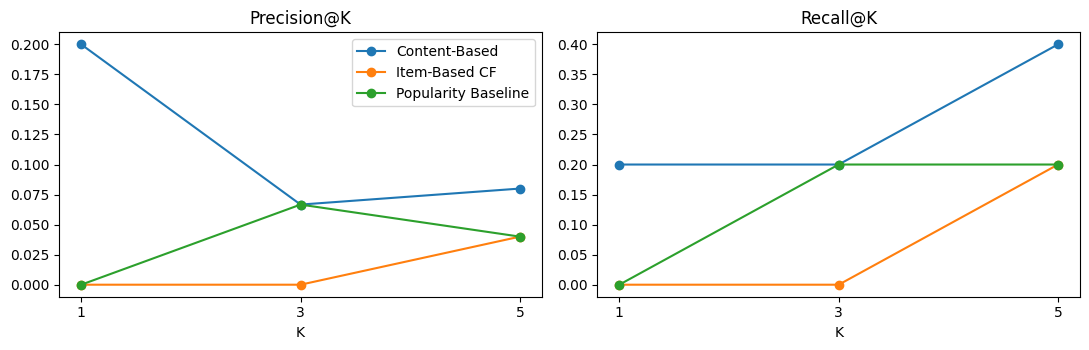

In [20]:
rows = []
for k in [1, 3, 5]:
    for name, fn in [("Popularity Baseline", recommend_popularity),
                     ("Content-Based", recommend_content),
                     ("Item-Based CF", recommend_cf)]:
        r = evaluate_ranking(fn, k)
        rows.append({"K": k, "Model": name,
                     "Precision@K": r[f"Precision@{k}"], "Recall@K": r[f"Recall@{k}"], "NDCG@K": r[f"NDCG@{k}"]})
k_results = pd.DataFrame(rows)
display(k_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, g in k_results.groupby("Model"):
    axes[0].plot(g["K"], g["Precision@K"], marker="o", label=name)
    axes[1].plot(g["K"], g["Recall@K"], marker="o", label=name)
axes[0].set_title("Precision@K"); axes[1].set_title("Recall@K")
for ax in axes:
    ax.set_xlabel("K"); ax.set_xticks([1, 3, 5])
axes[0].legend()
plt.tight_layout()
plt.show()

Explanation. As K increases, Recall@K cannot but remain the same or increase (the larger the list, the more opportunities to include the one relevant item), while Precision@K cannot but decrease, as the denominator K increases, while the numerator (number of relevant items for each user) does not exceed one. This is true for Content-Based: Recall varies from 0.20 to 0.20 to 0.40, while Precision varies from 0.20 to 0.07 to 0.08. At K = 1, only Content-Based system reaches a hit (only one user), while at K = 5, it remains the best on Recall (0.40 compared to 0.20 of Popularity and CF). CF achieves its first hit only at K = 5 (Recall 0.20), which proves that the order of hits in CF is bad.

## Summary
| Question | Answer |
|---|---|
| Best for rating prediction | Item-Based CF (MAE 0.924, RMSE 1.070) |
| Best for ranking | Content-Based (NDCG@3 0.20); CF scored 0 |
| Coverage / novelty / diversity | CF highest coverage (85%) and diversity; Content-Based lowest novelty/diversity; Popularity lowest coverage (35%) |
| Final recommendation | Content-Based (ideally evolving into a hybrid) |